# Validation statistique du tableau de bord

Le tableau de bord Power BI repère les segments où les sinistres coûtent le plus cher.
Ce notebook vérifie que ces conclusions tiennent statistiquement. Il répond à quatre questions :

1. **Les chiffres du tableau de bord sont-ils reproductibles ?** Je recalcule les indices avec Python.
2. **Les résultats dépendent-ils de quelques sinistres exceptionnels ?** J'analyse les sinistres graves et l'écrêtement.
3. **Les écarts sont-ils significatifs ?** Je calcule des intervalles de confiance sur la fréquence.
4. **Quel facteur explique vraiment le risque ?** J'estime un GLM de Poisson sur la fréquence, avec l'âge, la puissance et le Bonus-Malus.

**Indicateur utilisé : l'indice de prime pure.** C'est le coût des sinistres par année d'exposition d'un segment, divisé par celui du portefeuille (100 % = moyenne).
Ce n'est pas une rentabilité, car les primes réellement payées ne sont pas dans les données.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

DATA = Path("../data")
FIG = Path("../docs/figures")
FIG.mkdir(parents=True, exist_ok=True)

BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#8a8a8a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Données et contrôles

Les données sont le jeu public **freMTPL2** : un fichier de contrats (`freMTPL2freq`) et un fichier de sinistres avec leur montant (`freMTPL2sev`).
Placez les deux fichiers CSV dans le dossier `data/` (voir le README).

Le nombre et le coût des sinistres par contrat sont **recalculés à partir du fichier des sinistres**, pour que fréquence et coût portent exactement sur les mêmes sinistres.

In [2]:
freq = pd.read_csv(DATA / "freMTPL2freq.csv", usecols=lambda c: not c.startswith("Unnamed") and c != "")
sev = pd.read_csv(DATA / "freMTPL2sev.csv")

# Sinistres rattachés à un contrat existant
orphelins = ~sev["IDpol"].isin(freq["IDpol"])
print(f"Sinistres sans contrat correspondant : {orphelins.sum()} ({sev.loc[orphelins, 'ClaimAmount'].sum():,.0f} €), exclus")
sev = sev[~orphelins].copy()

agg = sev.groupby("IDpol")["ClaimAmount"].agg(cout="sum", nb="count")
df = freq.drop(columns=[c for c in ("ClaimNb", "ClaimTotal") if c in freq.columns]).join(agg, on="IDpol")
df[["cout", "nb"]] = df[["cout", "nb"]].fillna(0)

# Règles métier
print("Expositions > 1 an, ramenées à 1 :", (df["Exposure"] > 1).sum())
df["Exposure"] = df["Exposure"].clip(upper=1)
assert (df["DrivAge"] >= 18).all() and df["Exposure"].gt(0).all()
assert df["BonusMalus"].between(50, 350).all()

print(f"Contrats : {len(df):,} | sinistres : {df['nb'].sum():,.0f} | exposition : {df['Exposure'].sum():,.2f} années")
print(f"Fréquence : {df['nb'].sum() / df['Exposure'].sum():.2%} | coût moyen : {df['cout'].sum() / df['nb'].sum():,.2f} €")

Sinistres sans contrat correspondant : 256 (920,350 €), exclus
Expositions > 1 an, ramenées à 1 : 0
Contrats : 678,007 | sinistres : 26,383 | exposition : 358,358.81 années
Fréquence : 7.36% | coût moyen : 2,265.76 €


In [3]:
# Mêmes tranches que dans Power BI
df["Âge"] = pd.cut(df["DrivAge"], [17, 25, 40, 60, 200], labels=["Jeune (18-25)", "Confirmé (26-40)", "Expérimenté (41-60)", "Senior (61+)"])
df["Puissance"] = pd.cut(df["VehPower"], [0, 6, 9, 99], labels=["Faible (4-6)", "Moyenne (7-9)", "Élevée (10+)"])
df["Bonus-Malus"] = pd.cut(df["BonusMalus"], [0, 79, 99, 100, 150, 999],
                           labels=["Bonus fort (50-79)", "Bonus léger (80-99)", "Neutre (100)", "Malus (101-150)", "Malus fort (>150)"])

## 2. Reproduction des indices du tableau de bord

Indice brut d'un segment = (coût / exposition du segment) / (coût / exposition du portefeuille).

In [4]:
def tableau(cles, data=None):
    data = df if data is None else data
    pp_total = data["cout"].sum() / data["Exposure"].sum()
    pp_total_ecr = data["cout_ecrete"].sum() / data["Exposure"].sum() if "cout_ecrete" in data else np.nan
    g = data.groupby(cles, observed=True).agg(polices=("IDpol", "size"), exposition=("Exposure", "sum"),
                                              sinistres=("nb", "sum"), cout=("cout", "sum"),
                                              **({"cout_ecrete": ("cout_ecrete", "sum")} if "cout_ecrete" in data else {}))
    g["frequence"] = g["sinistres"] / g["exposition"]
    g["cout_moyen"] = g["cout"] / g["sinistres"]
    g["indice_brut"] = g["cout"] / g["exposition"] / pp_total
    if "cout_ecrete" in g:
        g["indice_ecrete"] = g["cout_ecrete"] / g["exposition"] / pp_total_ecr
    return g

tableau("Âge")[["polices", "sinistres", "frequence", "cout_moyen", "indice_brut"]]

,polices,sinistres,frequence,cout_moyen,indice_brut
Âge,,,,,
Jeune (18-25),38895,"2,403.000",0.148,"5,121.624",4.547
Confirmé (26-40),235691,"8,179.000",0.072,"2,115.678",0.917
Expérimenté (41-60),300193,"11,832.000",0.072,"1,795.973",0.778
Senior (61+),103228,"3,969.000",0.061,"2,246.470",0.819


Les valeurs sont celles de la version initiale du tableau de bord : 454,7 % pour les jeunes conducteurs, 978,6 % pour un Bonus-Malus neutre.
La question est maintenant de savoir si elles sont fiables.

## 3. Sinistres graves : quelques sinistres pèsent très lourd

En assurance automobile, quelques sinistres corporels très graves peuvent représenter une part énorme du coût.
Un segment peut alors paraître très risqué parce qu'il contient **un** sinistre exceptionnel, et non parce que ses assurés sont plus risqués.

In [5]:
montants = sev["ClaimAmount"].sort_values(ascending=False).reset_index(drop=True)
SEUIL = montants.quantile(0.995)
graves = montants > SEUIL
print(f"Seuil des sinistres graves (99,5e percentile) : {SEUIL:,.0f} €")
print(f"{graves.sum()} sinistres graves ({graves.mean():.1%} des sinistres) = {montants[graves].sum() / montants.sum():.1%} du coût total")
print(f"Plus gros sinistre : {montants.iloc[0]:,.0f} € = {montants.iloc[0] / montants.sum():.1%} du coût total à lui seul")

top = sev.loc[sev["ClaimAmount"].idxmax(), "IDpol"]
df.loc[df["IDpol"] == top, ["DrivAge", "VehPower", "BonusMalus", "Region", "Âge", "Puissance", "Bonus-Malus"]]

Seuil des sinistres graves (99,5e percentile) : 34,495 €
132 sinistres graves (0.5% des sinistres) = 33.0% du coût total
Plus gros sinistre : 4,075,401 € = 6.8% du coût total à lui seul


,DrivAge,VehPower,BonusMalus,Region,Âge,Puissance,Bonus-Malus
150027,19,9,100,R24,Jeune (18-25),Moyenne (7-9),Neutre (100)


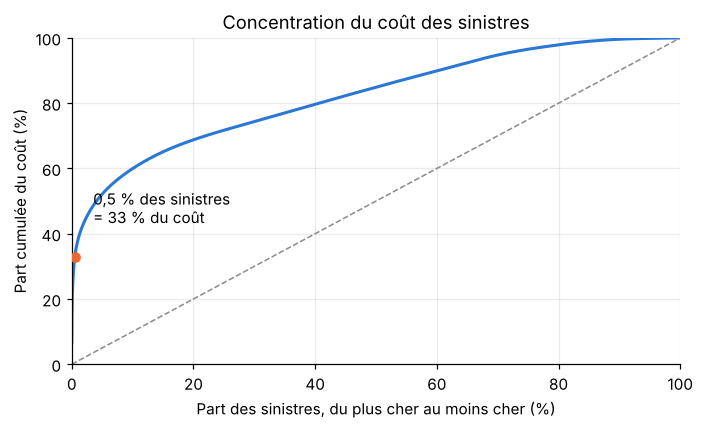

In [6]:
# Courbe de concentration du coût
part_sin = np.arange(1, len(montants) + 1) / len(montants)
part_cout = montants.cumsum() / montants.sum()
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(part_sin * 100, part_cout * 100, color=BLEU, lw=2)
ax.plot([0, 100], [0, 100], color=GRIS, lw=1, ls="--")
x = graves.mean() * 100; y = montants[graves].sum() / montants.sum() * 100
ax.scatter([x], [y], color=ORANGE, zorder=3)
ax.annotate(f"{x:.1f} % des sinistres\n= {y:.0f} % du coût".replace(".", ","), (x, y), xytext=(12, 22), textcoords="offset points")
ax.set_xlabel("Part des sinistres, du plus cher au moins cher (%)")
ax.set_ylabel("Part cumulée du coût (%)")
ax.set_title("Concentration du coût des sinistres")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
fig.tight_layout(); fig.savefig(FIG / "concentration_cout.png", dpi=150); plt.show()

**Écrêtement.** Chaque sinistre est plafonné au seuil (99,5e percentile). C'est la pratique actuarielle courante :
la partie qui dépasse est mutualisée sur tout le portefeuille, au lieu d'être imputée au segment où le hasard l'a fait tomber.

In [7]:
plafonne = sev.assign(ecrete=sev["ClaimAmount"].clip(upper=SEUIL)).groupby("IDpol")["ecrete"].sum()
df["cout_ecrete"] = df["IDpol"].map(plafonne).fillna(0)

comparaison = pd.concat({
    "Âge": tableau("Âge")[["sinistres", "indice_brut", "indice_ecrete"]],
    "Bonus-Malus": tableau("Bonus-Malus")[["sinistres", "indice_brut", "indice_ecrete"]],
    "Puissance": tableau("Puissance")[["sinistres", "indice_brut", "indice_ecrete"]],
})
comparaison

sinistres  indice_brut  indice_ecrete
Âge         Jeune (18-25)        2,403.000        4.547          2.253
            Confirmé (26-40)     8,179.000        0.917          0.978
            Expérimenté (41-60) 11,832.000        0.778          0.953
            Senior (61+)         3,969.000        0.819          0.845
Bonus-Malus Bonus fort (50-79)  20,315.000        0.751          0.848
            Bonus léger (80-99)  3,492.000        1.431          1.608
            Neutre (100)         1,320.000        9.786          3.588
            Malus (101-150)      1,202.000        4.187          4.796
            Malus fort (>150)       54.000        8.361         10.815
Puissance   Faible (4-6)        15,362.000        0.925          0.973
            Moyenne (7-9)        8,458.000        1.119          1.003
            Élevée (10+)         2,563.000        1.064          1.169

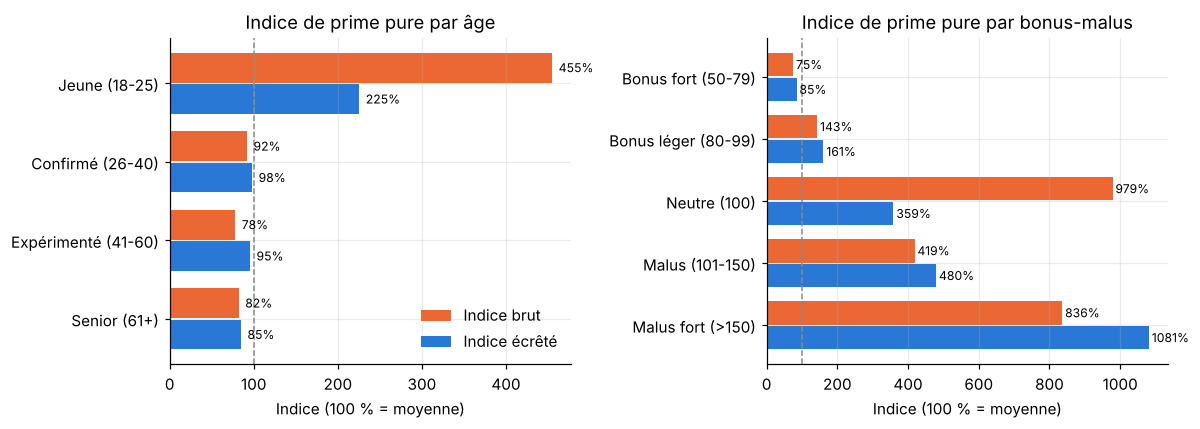

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=False)
for ax, cle in zip(axes, ["Âge", "Bonus-Malus"]):
    t = tableau(cle)[::-1]
    y = np.arange(len(t))
    ax.barh(y + 0.2, t["indice_brut"] * 100, height=0.38, color=ORANGE, label="Indice brut")
    ax.barh(y - 0.2, t["indice_ecrete"] * 100, height=0.38, color=BLEU, label="Indice écrêté")
    for yi, (b, e) in enumerate(zip(t["indice_brut"], t["indice_ecrete"])):
        ax.text(b * 100 + 8, yi + 0.2, f"{b:.0%}", va="center", fontsize=8)
        ax.text(e * 100 + 8, yi - 0.2, f"{e:.0%}", va="center", fontsize=8)
    ax.axvline(100, color=GRIS, ls="--", lw=1)
    ax.set_yticks(y, t.index); ax.set_title(f"Indice de prime pure par {cle.lower()}")
    ax.set_xlabel("Indice (100 % = moyenne)")
axes[0].legend(loc="lower right", frameon=False)
fig.tight_layout(); fig.savefig(FIG / "indice_brut_vs_ecrete.png", dpi=150); plt.show()

In [9]:
# Le croisement jeunes × puissance moyenne, avec et sans le plus gros sinistre
x = tableau(["Âge", "Puissance"])
jm = x.loc[("Jeune (18-25)", "Moyenne (7-9)")]
sans_top = df.assign(cout=np.where(df["IDpol"] == top, df["cout"] - montants.iloc[0], df["cout"]))
jm_sans = tableau(["Âge", "Puissance"], sans_top).loc[("Jeune (18-25)", "Moyenne (7-9)")]
moy_sans = sans_top["cout"].sum() / sans_top["nb"].sum()
print(f"Jeunes × puissance moyenne : indice brut {jm['indice_brut']:.0%}, sans le plus gros sinistre {jm_sans['indice_brut']:.0%}, écrêté {jm['indice_ecrete']:.0%}")
print(f"Coût moyen : {jm['cout_moyen'] / (df['cout'].sum() / df['nb'].sum()):.1f} fois la moyenne avec ce sinistre, "
      f"{jm_sans['cout_moyen'] / moy_sans:.1f} fois sans lui")
print(f"Fréquence : {jm['frequence'] / (df['nb'].sum() / df['Exposure'].sum()):.1f} fois la moyenne (inchangée)")

Jeunes × puissance moyenne : indice brut 898%, sans le plus gros sinistre 322%, écrêté 295%
Coût moyen : 3.9 fois la moyenne avec ce sinistre, 1.4 fois sans lui
Fréquence : 2.3 fois la moyenne (inchangée)


**Conclusion de cette partie.** Le chiffre de 897,6 % pour les jeunes conducteurs avec une voiture de puissance moyenne venait presque entièrement d'un seul sinistre de 4,1 M€.
Le « coût moyen 3,9 fois plus élevé » retombe à environ 1,4 fois sans ce sinistre. En revanche, la **fréquence 2,3 fois plus élevée** n'en dépend pas.

## 4. Crédibilité : intervalles de confiance sur la fréquence

Le nombre de sinistres d'un segment suit approximativement une loi de Poisson.
L'intervalle de confiance exact à 95 % de la fréquence se calcule avec la loi du khi-deux.
Un segment avec peu de sinistres a un intervalle large, et son indice doit être lu avec prudence.

In [10]:
def ic_poisson(n, expo, niveau=0.95):
    a = 1 - niveau
    bas = np.where(n > 0, stats.chi2.ppf(a / 2, 2 * n) / 2, 0) / expo
    haut = stats.chi2.ppf(1 - a / 2, 2 * n + 2) / 2 / expo
    return bas, haut

def credibilite(cle):
    t = tableau(cle)[["sinistres", "exposition", "frequence"]].copy()
    t["ic_bas"], t["ic_haut"] = ic_poisson(t["sinistres"].values, t["exposition"].values)
    t["largeur_relative"] = (t["ic_haut"] - t["ic_bas"]) / t["frequence"]
    return t

credibilite("Bonus-Malus")

,sinistres,exposition,frequence,ic_bas,ic_haut,largeur_relative
Bonus-Malus,,,,,,
Bonus fort (50-79),"20,315.000","318,738.081",0.064,0.063,0.065,0.028
Bonus léger (80-99),"3,492.000","29,809.492",0.117,0.113,0.121,0.067
Neutre (100),"1,320.000","6,240.503",0.212,0.200,0.223,0.109
Malus (101-150),"1,202.000","3,475.601",0.346,0.327,0.366,0.114
Malus fort (>150),54.000,95.128,0.568,0.426,0.741,0.554


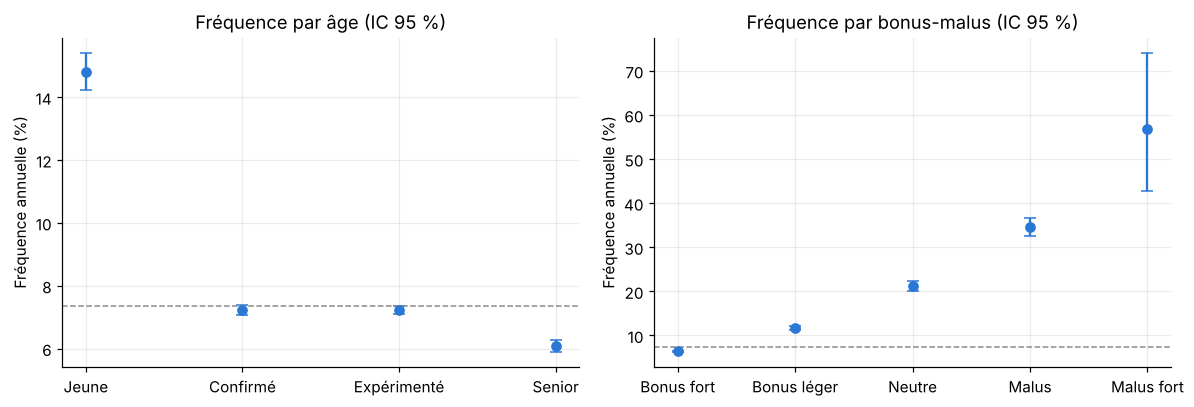

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, cle in zip(axes, ["Âge", "Bonus-Malus"]):
    t = credibilite(cle)
    x = np.arange(len(t))
    ax.errorbar(x, t["frequence"] * 100, yerr=[(t["frequence"] - t["ic_bas"]) * 100, (t["ic_haut"] - t["frequence"]) * 100],
                fmt="o", color=BLEU, ecolor=BLEU, capsize=4, ms=6)
    ax.axhline(df["nb"].sum() / df["Exposure"].sum() * 100, color=GRIS, ls="--", lw=1)
    ax.set_xticks(x, [l.split(" (")[0] for l in t.index], rotation=0)
    ax.set_ylabel("Fréquence annuelle (%)"); ax.set_title(f"Fréquence par {cle.lower()} (IC 95 %)")
fig.tight_layout(); fig.savefig(FIG / "frequence_ic.png", dpi=150); plt.show()

Les intervalles sont très serrés pour presque tous les segments : les écarts de fréquence sont réels.
Seul le **Malus fort** (54 sinistres) a un intervalle large, environ de 43 % à 74 % : on sait qu'il est très risqué, mais pas précisément à quel point.
La fréquence augmente de façon régulière avec le coefficient Bonus-Malus, ce qui montre que le système **fonctionne**.

## 5. GLM de Poisson : quel facteur explique vraiment la fréquence ?

Le tableau de bord croise les variables deux à deux. Mais l'âge et le Bonus-Malus sont liés : un nouveau conducteur commence à 100.
Un **GLM de Poisson** avec l'exposition en offset estime l'effet de chaque variable **toutes choses égales par ailleurs** :

$$\log E[N_i] = \log(\text{exposition}_i) + \beta_0 + \beta_{\text{âge}} + \beta_{\text{puissance}} + \beta_{\text{BM}}$$

Une relativité $e^{\beta}$ de 1,30 signifie une fréquence 30 % plus élevée que la classe de référence.
Les données sont agrégées par case (âge × puissance × Bonus-Malus), ce qui donne exactement les mêmes estimations qu'au niveau du contrat.

In [12]:
print("Part des jeunes conducteurs parmi les Bonus-Malus à 100 :",
      f"{(df.loc[df['BonusMalus'] == 100, 'Âge'] == 'Jeune (18-25)').mean():.0%}",
      f"(contre {(df['Âge'] == 'Jeune (18-25)').mean():.1%} dans le portefeuille)")

cases = (df.groupby(["Âge", "Puissance", "Bonus-Malus"], observed=True)
           .agg(n=("nb", "sum"), expo=("Exposure", "sum")).reset_index())
cases.columns = ["age", "puissance", "bm", "n", "expo"]
ref = lambda v, r: f"C({v}, Treatment('{r}'))"
A, P, B = ref("age", "Expérimenté (41-60)"), ref("puissance", "Faible (4-6)"), ref("bm", "Bonus fort (50-79)")

def glm(formule):
    return smf.glm(formule, cases, family=sm.families.Poisson(), offset=np.log(cases["expo"])).fit()

modeles = {
    "M1 : âge + puissance": glm(f"n ~ {A} + {P}"),
    "M2 : M1 + Bonus-Malus": glm(f"n ~ {A} + {P} + {B}"),
    "M3 : M2 + âge × puissance": glm(f"n ~ {A} * {P} + {B}"),
}
pd.DataFrame({k: {"déviance": m.deviance, "ddl": m.df_resid, "AIC": m.aic} for k, m in modeles.items()}).T

Part des jeunes conducteurs parmi les Bonus-Malus à 100 : 42% (contre 5.7% dans le portefeuille)


,déviance,ddl,AIC
M1 : âge + puissance,"3,337.043",54.000,"3,699.699"
M2 : M1 + Bonus-Malus,175.650,50.000,546.306
M3 : M2 + âge × puissance,137.550,44.000,520.206


In [13]:
def relativites(m):
    ci = m.conf_int()
    t = pd.DataFrame({"relativité": np.exp(m.params), "IC bas": np.exp(ci[0]), "IC haut": np.exp(ci[1]), "p-valeur": m.pvalues})
    t.index = (t.index.str.replace(r"C\((\w+), Treatment\('[^']*'\)\)\[T\.", r"\1 = ", regex=True)
                      .str.replace("]", "", regex=False))
    return t.drop("Intercept")

age_m1 = relativites(modeles["M1 : âge + puissance"]).filter(like="age =", axis=0)
age_m2 = relativites(modeles["M2 : M1 + Bonus-Malus"]).filter(like="age =", axis=0)
pd.concat({"Sans Bonus-Malus (M1)": age_m1[["relativité", "IC bas", "IC haut"]],
           "Avec Bonus-Malus (M2)": age_m2[["relativité", "IC bas", "IC haut"]]}, axis=1)

Sans Bonus-Malus (M1)                 \
                                  relativité IC bas IC haut   
age = Jeune (18-25)                    2.073  1.984   2.166   
age = Confirmé (26-40)                 1.005  0.977   1.034   
age = Senior (61+)                     0.845  0.815   0.876   

                       Avec Bonus-Malus (M2)                 
                                  relativité IC bas IC haut  
age = Jeune (18-25)                    1.046  0.993   1.101  
age = Confirmé (26-40)                 0.878  0.853   0.904  
age = Senior (61+)                     0.866  0.835   0.898

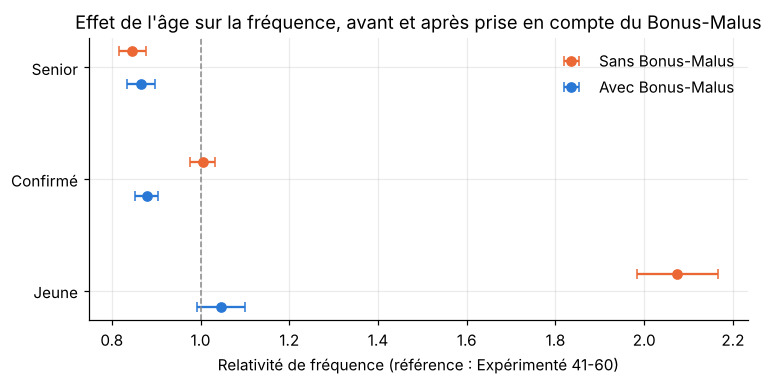

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
labels = [i.replace("age = ", "").split(" (")[0] for i in age_m1.index]
y = np.arange(len(labels))
for decal, t, couleur, nom in [(0.15, age_m1, ORANGE, "Sans Bonus-Malus"), (-0.15, age_m2, BLEU, "Avec Bonus-Malus")]:
    ax.errorbar(t["relativité"], y + decal, xerr=[t["relativité"] - t["IC bas"], t["IC haut"] - t["relativité"]],
                fmt="o", color=couleur, capsize=3, label=nom)
ax.axvline(1, color=GRIS, ls="--", lw=1)
ax.set_yticks(y, labels); ax.set_xlabel("Relativité de fréquence (référence : Expérimenté 41-60)")
ax.set_title("Effet de l'âge sur la fréquence, avant et après prise en compte du Bonus-Malus")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "glm_age_bonus_malus.png", dpi=150); plt.show()

In [15]:
relativites(modeles["M2 : M1 + Bonus-Malus"]).filter(like="bm =", axis=0)

,relativité,IC bas,IC haut,p-valeur
bm = Bonus léger (80-99),1.831,1.760,1.906,0.000
bm = Neutre (100),3.252,3.064,3.452,0.000
bm = Malus (101-150),5.352,5.033,5.692,0.000
bm = Malus fort (>150),8.750,6.694,11.438,0.000


In [16]:
# Test du rapport de vraisemblance : l'interaction âge × puissance est-elle significative ?
m2, m3 = modeles["M2 : M1 + Bonus-Malus"], modeles["M3 : M2 + âge × puissance"]
lr = m2.deviance - m3.deviance
ddl = int(m2.df_resid - m3.df_resid)
print(f"LR = {lr:.1f} pour {ddl} ddl, p = {stats.chi2.sf(lr, ddl):.1e}")
relativites(m3).filter(like=":", axis=0)

LR = 38.1 pour 6 ddl, p = 1.1e-06


,relativité,IC bas,IC haut,p-valeur
age = Jeune (18-25):puissance = Moyenne (7-9),1.253,1.137,1.381,0.000
age = Confirmé (26-40):puissance = Moyenne (7-9),1.144,1.075,1.217,0.000
age = Senior (61+):puissance = Moyenne (7-9),1.036,0.957,1.121,0.379
age = Jeune (18-25):puissance = Élevée (10+),1.099,0.890,1.357,0.382
age = Confirmé (26-40):puissance = Élevée (10+),1.161,1.056,1.278,0.002
age = Senior (61+):puissance = Élevée (10+),0.961,0.844,1.095,0.552


In [17]:
# Surdispersion : la variance dépasse la moyenne (variables absentes du modèle : région, âge du véhicule, densité...).
phi = m3.pearson_chi2 / m3.df_resid
print(f"Dispersion (Pearson χ² / ddl) : {phi:.2f}")

# Correction quasi-Poisson : mêmes coefficients, erreurs-types multipliées par racine(phi)
q2 = smf.glm(f"n ~ {A} + {P} + {B}", cases, family=sm.families.Poisson(), offset=np.log(cases["expo"])).fit(scale="X2")
q3 = smf.glm(f"n ~ {A} * {P} + {B}", cases, family=sm.families.Poisson(), offset=np.log(cases["expo"])).fit(scale="X2")
F = (q2.deviance - q3.deviance) / ddl / phi
print(f"Test global de l'interaction après correction : F = {F:.2f}, p = {stats.f.sf(F, ddl, q3.df_resid):.2f}")
rq = relativites(q3)
print(f"Jeunes × puissance moyenne : relativité {rq.iloc[:, 0].filter(like='Jeune (18-25):puissance = Moyenne').iloc[0]:.2f}, "
      f"p = {rq['p-valeur'].filter(like='Jeune (18-25):puissance = Moyenne').iloc[0]:.3f}")
print(f"Jeunes (M2 corrigé) : p = {relativites(q2)['p-valeur'].filter(like='Jeune').iloc[0]:.2f}")

Dispersion (Pearson χ² / ddl) : 3.14
Test global de l'interaction après correction : F = 2.02, p = 0.08
Jeunes × puissance moyenne : relativité 1.25, p = 0.010
Jeunes (M2 corrigé) : p = 0.37


**Lecture.**

- **Sans le Bonus-Malus**, les jeunes conducteurs ont une fréquence environ **2 fois** plus élevée que les 41-60 ans.
- **Avec le Bonus-Malus**, cet effet disparaît : relativité de 1,05, non significative. Le Bonus-Malus capte déjà le sur-risque des jeunes,
  parce qu'ils sont presque tous à 100 ou au-dessus (42 % des contrats à 100 sont des jeunes). La fréquence est **3,3 fois** plus élevée à 100 qu'en bonus fort, et **5 à 9 fois** plus élevée en malus.
- **L'interaction âge × puissance** : les jeunes avec un véhicule de puissance moyenne ont une fréquence environ **25 % plus élevée** que ce que prédisent l'âge et la puissance séparément.
  Ce coefficient reste significatif après correction de la surdispersion (p ≈ 0,01), mais le test global de l'interaction devient limite (p ≈ 0,08).
  L'intuition du tableau de bord était donc juste, mais il s'agit d'un **signal modeste** (+25 % de fréquence), pas d'un indice multiplié par 9.
- **Surdispersion (≈ 3)** : des variables absentes du modèle (région, âge du véhicule, densité) font varier la fréquence. La correction quasi-Poisson élargit les intervalles d'un facteur 1,8 environ.
  Les conclusions sur le Bonus-Malus et l'âge ne changent pas.

## 6. Conclusions corrigées

| Résultat initial du tableau de bord | Ce que montre la validation |
|---|---|
| Jeunes conducteurs : indice de 454,7 % | Fréquence 2 fois plus élevée, robuste (IC serré). L'indice écrêté est de **225 %** : le reste de l'écart venait surtout d'un seul sinistre de 4,1 M€. |
| Jeunes × puissance moyenne : 897,6 % | Signal modeste : **+25 % de fréquence** (p ≈ 0,01 après correction de la surdispersion). L'indice de 897,6 % venait d'un seul sinistre ; l'indice écrêté est d'environ **295 %**. |
| Bonus-Malus neutre : 978,6 %, « limite du système » | Indice écrêté de **359 %**. Le Bonus-Malus **fonctionne** : la fréquence croît régulièrement avec le coefficient, et il explique l'essentiel de l'effet âge. Le niveau 100 regroupe surtout des **nouveaux conducteurs** : c'est un enjeu de tarification à la souscription, pas une faille du système. |
| Région R21 : 239,6 % | Dû à un sinistre de 369 000 € : l'indice écrêté est proche de la moyenne. |

**Limites.** Les primes réelles ne sont pas disponibles, donc l'indice compare des coûts et non une rentabilité.
L'analyse de la sévérité reste descriptive : un GLM Gamma sur les coûts écrêtés compléterait la tarification.
Enfin, les données sont une photographie à une date donnée, sans historique.